In [ ]:


!nvidia-smi

Sun Oct 18 00:43:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!wget -O /content/data.zip https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip

--2026-10-18 00:43:18--  https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip
Resolving s3.us-west-1.amazonaws.com (s3.us-west-1.amazonaws.com)... 16.15.0.38, 16.15.0.194, 16.15.4.245, ...
Connecting to s3.us-west-1.amazonaws.com (s3.us-west-1.amazonaws.com)|16.15.0.38|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45172966 (43M) [application/zip]
Saving to: ‘/content/data.zip’

/content/data.zip   100%[===================>]  43.08M  67.0MB/s    in 0.6s    

2026-10-18 00:43:19 (67.0 MB/s) - ‘/content/data.zip’ saved [45172966/45172966]



In [ ]:
!unzip -q /content/data.zip -d /content/custom_data

replace /content/custom_data/classes.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

!python train_val_split.py --datapath /content/custom_data --train_pct=0.9

In [ ]:
!pip install ultralytics

In [ ]:
import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):
  if not os.path.exists(path_to_classes_txt):
    print(f"classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}")
    return
  with open(path_to_classes_txt, "r") as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  data = {
      "path": "/content/data",
      "train": "train/images",
      "val": "validation/images",
      "nc": number_of_classes,
      "names": classes
  }

  with open(path_to_data_yaml, "w") as f:
    yaml.dump(data, f, sort_keys=False)
  print(f"Created config file at {path_to_data_yaml}")

  return

path_to_classes_txt = "/content/custom_data/classes.txt"
path_to_data_yaml = "/content/data.yaml"

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print("\nFile contents:\n")
!cat /content/data.yaml

In [ ]:
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=60 imgsz=640

In [ ]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f"/content/runs/detect/predict/*.jpg")[:10]:
  display(Image(filename=image_path, width=400))
  print("\n")

In [ ]:
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

In [ ]:
!wget -O /content/yolo_detect.py https://www.ejtech.io/code/yolo_detect.py

Loading model...
Model loaded successfully!


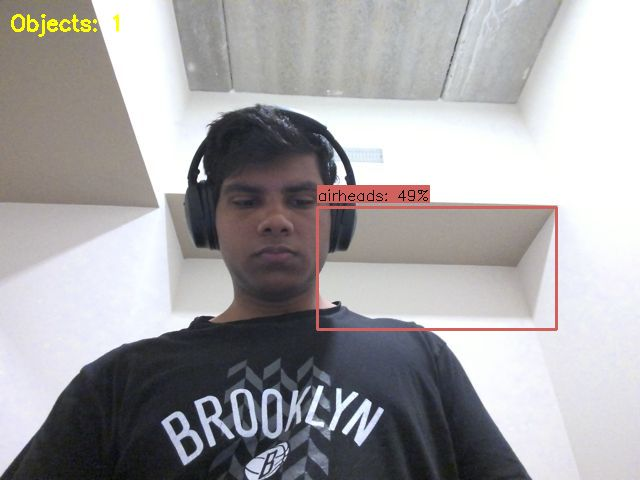

Starting live stream... Allow camera access if your browser prompts you.


<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from google.colab import output
from base64 import b64decode, b64encode
import cv2
import numpy as np
from ultralytics import YOLO
import time

# 1. Load your trained YOLO model
MODEL_PATH = '/content/my_model/my_model.pt'
print("Loading model...")
model = YOLO(MODEL_PATH, task='detect')
labels = model.names
print("Model loaded successfully!")

# 2. JavaScript to capture frames from the laptop webcam and send to Python
def js_stream_code():
    js = Javascript('''
        async function startStream() {
            const container = document.createElement('div');
            container.id = 'webcam-container';
            document.querySelector('#output-area').appendChild(container);

            const video = document.createElement('video');
            video.width = 640;
            video.height = 480;
            video.autoplay = true;
            video.playsInline = true;
            video.style.transform = 'scaleX(-1)';
            container.appendChild(video);

            const canvas = document.createElement('canvas');
            canvas.width = 640;
            canvas.height = 480;
            const ctx = canvas.getContext('2d');

            try {
                const stream = await navigator.mediaDevices.getUserMedia({ video: { width: 640, height: 480 } });
                video.srcObject = stream;
            } catch (err) {
                alert("Webcam access denied or unavailable: " + err);
                return;
            }

            window.streaming = true;

            async function captureLoop() {
                if (!window.streaming) {
                    video.srcObject.getTracks().forEach(track => track.stop());
                    container.remove();
                    return;
                }

                ctx.drawImage(video, 0, 0, 640, 480);
                const data = canvas.toDataURL('image/jpeg', 0.8);

                // Send frame to Python backend function
                google.colab.kernel.invokeFunction('notebook.process_frame', [data], {});

                // Control frame rate (~15 fps to keep browser responsive)
                setTimeout(() => {
                    requestAnimationFrame(captureLoop);
                }, 60);
            }

            requestAnimationFrame(captureLoop);
        }

        // Ensure output-area exists or fallback to document.body
        if (!document.querySelector('#output-area')) {
            const outArea = document.createElement('div');
            outArea.id = 'output-area';
            document.body.appendChild(outArea);
        }

        startStream();
    ''')
    display(js)

# Create a placeholder for the live processed video output
processed_img_handle = display(None, display_id=True)

# 3. Python backend function that receives frames, runs YOLO, and updates the display
def process_frame(data_uri):
    try:
        header, encoded = data_uri.split(',', 1)
        image_bytes = b64decode(encoded)
        np_arr = np.frombuffer(image_bytes, np.uint8)
        frame = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

        if frame is None:
            return

        # Run YOLO inference
        results = model(frame, verbose=False)
        detections = results[0].boxes
        object_count = 0

        # Tableau 10 color scheme
        bbox_colors = [
            (164, 120, 87), (68, 148, 228), (93, 97, 209), (178, 182, 133), (88, 159, 106),
            (96, 202, 231), (159, 124, 168), (169, 162, 241), (98, 118, 150), (172, 176, 184)
        ]

        # Draw detections
        for i in range(len(detections)):
            conf = detections[i].conf.item()
            if conf > 0.4:  # Confidence threshold
                xyxy = detections[i].xyxy.cpu().numpy().squeeze().astype(int)
                xmin, ymin, xmax, ymax = xyxy

                classidx = int(detections[i].cls.item())
                classname = labels[classidx]

                color = bbox_colors[classidx % 10]
                cv2.rectangle(frame, (xmin, ymin), (xmax, ymax), color, 2)

                label = f'{classname}: {int(conf * 100)}%'
                labelSize, baseLine = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
                label_ymin = max(ymin, labelSize[1] + 10)

                cv2.rectangle(frame, (xmin, label_ymin - labelSize[1] - 10), (xmin + labelSize[0], label_ymin + baseLine - 10), color, cv2.FILLED)
                cv2.putText(frame, label, (xmin, label_ymin - 7), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1)
                object_count += 1

        cv2.putText(frame, f'Objects: {object_count}', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

        # Encode processed frame back to JPG
        _, encoded_img = cv2.imencode('.jpg', frame, [int(cv2.IMWRITE_JPEG_QUALITY), 80])

        # Update the image display handle live in the notebook cell output
        processed_img_handle.update(Image(data=encoded_img.tobytes()))

    except Exception as e:
        print(f"Error processing frame: {e}")

# Register the callback function
output.register_callback('notebook.process_frame', process_frame)

print("Starting live stream... Allow camera access if your browser prompts you.")
js_stream_code()